We create the synthetic dataset from Appendix B.1 and Table 7: 10 numeric features, 5 noise features and a 3-category column.
It has 83,333 rows per category, so 249,999 rows in total (the paper uses about 250K).
Each row’s label comes from the jumpy formula with category gates (Eq. 8), then the sigmoid and a Bernoulli draw.
Coefficients were found by a seed search for balanced classes (seed 1), giving an oracle AUC of 0.8645.

In [1]:
import numpy as np
import pandas as pd
import warnings
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore", category=RuntimeWarning)   # hides harmless overflow warnings from exp()

# ---------- Settings from the paper (Appendix B.1, Table 7) ----------
number_of_numeric_features = 10      # x1 ... x10
number_of_noise_features = 5         # noise1 ... noise5 (not in the formula)
number_of_segments = 3               # the categorical column has 3 categories
correlation_within_pair = 0.5        # Eq. 4
rows_per_segment = 83333             # 3 x 83,333 = 249,999 rows (paper: 250K)

# ---------- Covariance matrix (Eq. 4): neighbouring pairs correlated at 0.5 ----------
covariance_matrix = np.eye(number_of_numeric_features)
for i in range(0, number_of_numeric_features, 2):
    covariance_matrix[i, i + 1] = covariance_matrix[i + 1, i] = correlation_within_pair

# ---------- The data generator: one dataset from a seed ----------
def make_dataset(seed, beta, rows_per_segment=rows_per_segment):
    rows = rows_per_segment * number_of_segments
    gen = np.random.default_rng(seed)

    # Part 3: feature values
    values = gen.multivariate_normal(np.zeros(number_of_numeric_features), covariance_matrix, rows)
    data = pd.DataFrame(values, columns=[f"x{i}" for i in range(1, 11)])
    for j in range(1, number_of_noise_features + 1):
        data[f"noise{j}"] = gen.standard_normal(rows)            # pure random numbers
    data["cat"] = gen.permutation(np.arange(rows) % number_of_segments)   # categories 0,1,2, equal sizes

    # Part 1: the ten terms of the jumpy GAM local formula (Eq. 3)
    x1, x2, x3, x4, x5, x6, x7, x8, x9, x10 = [data[f"x{i}"].values for i in range(1, 11)]
    t1  = beta[0] * np.abs(x1) * (np.abs(x1) < 2)
    t2  = beta[1] * x2**2 * (x2 > 1)
    t3  = beta[2] * np.log(np.abs(x3) + 1) * (np.abs(x3) > 1)
    t4  = np.exp(beta[3] * x4) * (x4 < 0)
    t5  = 1 / (beta[4] * np.abs(x5) + 1)
    t6  = beta[5] * np.maximum(1, x6 + x7)
    t7  = beta[6] * (x7 < 1)
    t8  = beta[7] * (np.abs(x8) > 2)
    t9  = beta[8] * x9 * (x9 < -1)
    t10 = beta[9] * np.maximum(0, x10)

    # Gatekeepers (Eq. 8): each category only uses its own terms
    c = data["cat"].values
    logit = ((c == 0) * (t1 + t2 + t3)
           + (c == 1) * (t4 + t5 + t6)
           + (c == 2) * (t7 + t8 + t9 + t10))

    # Part 4: logit -> probability (Eq. 5) -> random 0/1 label
    probability = 1 / (1 + np.exp(-logit))
    data["y"] = gen.binomial(1, probability)
    data["true_probability"] = probability
    return data

# ---------- Part 2: coefficients in [-3, 3], searched until the classes are balanced ----------
# (the paper says classes were checked to be balanced but not how; this search is my method)
# The search uses small trial datasets (3 x 10,000 rows) so it runs fast.
found = False
for coefficient_seed in range(300):
    beta = np.random.default_rng(coefficient_seed).uniform(-3, 3, number_of_numeric_features)
    trial = make_dataset(9999, beta, rows_per_segment=10000)
    share_of_class_1 = trial["y"].mean()
    oracle_auc = roc_auc_score(trial["y"], trial["true_probability"])
    if 0.45 <= share_of_class_1 <= 0.55 and 0.83 <= oracle_auc <= 0.89:
        found = True
        break

print("Coefficient seed found:", coefficient_seed if found else "NONE in 300 tries")
print("Coefficients:", beta.round(2))

# ---------- Create one full-size dataset (validation set 1) and check it ----------
check = make_dataset(2000, beta)
print("\nRows:", len(check))
print("Rows per category:", check["cat"].value_counts().sort_index().tolist())
print("Share of class 1:", check["y"].mean().round(3))
print("Oracle AUC:", round(float(roc_auc_score(check["y"], check["true_probability"])), 4))
print("Correlation x1,x2 / x1,x3:", check["x1"].corr(check["x2"]).round(2), "/", check["x1"].corr(check["x3"]).round(2))

Coefficient seed found: 1
Coefficients: [ 0.07  2.7  -2.14  2.69 -1.13 -0.46  1.97 -0.54  0.3  -2.83]

Rows: 249999
Rows per category: [83333, 83333, 83333]
Share of class 1: 0.546
Oracle AUC: 0.8645
Correlation x1,x2 / x1,x3: 0.5 / 0.0


We define the standard preprocessing: standardizing numeric columns using the training data’s mean and spread.
We also define the four encodings: one-hot, reverse Helmert, frequency and binary.
These add 3, 2, 1 and 2 columns respectively.
The checks confirm the column counts and that standardized x1 has mean 0 and standard deviation 1.


In [2]:
numeric_columns = [f"x{i}" for i in range(1, 11)] + [f"noise{j}" for j in range(1, 6)]
encoding_methods = ["one_hot", "helmert", "frequency", "binary"]

def standardize(data, reference=None):
    # Standard preprocessing: rescale numeric columns using the TRAINING data's mean and spread
    reference = data if reference is None else reference
    return (data[numeric_columns] - reference[numeric_columns].mean()) / reference[numeric_columns].std()

def encode_category(data, method, reference=None):
    reference = data if reference is None else reference
    category = data["cat"]
    if method == "one_hot":
        return pd.DataFrame({f"cat_is_{k}": (category == k).astype(int) for k in range(3)})
    if method == "helmert":                       # reverse Helmert, paper Table 10 pattern
        return pd.DataFrame({
            "helmert_1": category.map({0: -0.5, 1: 0.5, 2: 0.0}),
            "helmert_2": category.map({0: -1/3, 1: -1/3, 2: 2/3})})
    if method == "frequency":                     # share of rows in each category (from training data)
        share_of_each_category = reference["cat"].value_counts(normalize=True)
        return pd.DataFrame({"cat_frequency": category.map(share_of_each_category)})
    if method == "binary":                        # categories 0,1,2 -> codes 1,2,3 -> 01, 10, 11
        code = category + 1
        return pd.DataFrame({"binary_high_bit": (code // 2) % 2, "binary_low_bit": code % 2})

def prepare_features(data, method, reference=None):
    return pd.concat([standardize(data, reference), encode_category(data, method, reference)], axis=1)

# ---------- Check on the dataset from Cell 1 ----------
for method in encoding_methods:
    table = prepare_features(check, method)
    print(f"{method:<10} -> {table.shape[1]} columns; new columns:",
          [c for c in table.columns if c not in numeric_columns])

print("\nFrequency values found:", prepare_features(check, "frequency")["cat_frequency"].unique().round(4))
print("\nHelmert values per category:")
print(encode_category(check, "helmert").assign(cat=check["cat"]).drop_duplicates()
      .sort_values("cat").round(3).to_string(index=False))

standardized = prepare_features(check, "one_hot")
print("\nStandardized x1: mean", round(float(standardized["x1"].mean()), 3),
      " std", round(float(standardized["x1"].std()), 3))

one_hot    -> 18 columns; new columns: ['cat_is_0', 'cat_is_1', 'cat_is_2']
helmert    -> 17 columns; new columns: ['helmert_1', 'helmert_2']
frequency  -> 16 columns; new columns: ['cat_frequency']
binary     -> 17 columns; new columns: ['binary_high_bit', 'binary_low_bit']

Frequency values found: [0.3333]

Helmert values per category:
 helmert_1  helmert_2  cat
      -0.5     -0.333    0
       0.5     -0.333    1
       0.0      0.667    2

Standardized x1: mean 0.0  std 1.0


We build the paper’s 3 tuning datasets (seeds 3000 to 3002), using sets 1 and 2 to train and set 3 to validate.
Our 2 + 1 split is our own choice, since the paper doesn’t specify one.
One XGBoost and one LightGBM model are trained with fixed settings to time them.
XGBoost took 6.4 s (AUC 0.8642) and LightGBM took 7.9 s (AUC 0.8617).


In [3]:
import time
import xgboost as xgb
import lightgbm as lgb

# The paper's 3 hyperparameter-tuning datasets (same coefficients, different random draws)
tuning_sets = [make_dataset(3000 + i, beta) for i in range(3)]
print("Tuning datasets built:", [len(d) for d in tuning_sets])

# Learn from tuning sets 1 and 2, score on tuning set 3 (one-hot columns = the paper's control group)
tuning_train = pd.concat([tuning_sets[0], tuning_sets[1]], ignore_index=True)
tuning_valid = tuning_sets[2]
X_tuning_train = prepare_features(tuning_train, "one_hot")
X_tuning_valid = prepare_features(tuning_valid, "one_hot", reference=tuning_train)
print("Training rows:", len(X_tuning_train), "| Validation rows:", len(X_tuning_valid))

# Timing test: one model of each type with fixed example settings
start = time.time()
test_xgb = xgb.XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, gamma=1,
                             tree_method="hist", random_state=0, eval_metric="logloss")
test_xgb.fit(X_tuning_train, tuning_train["y"])
xgb_seconds = time.time() - start
xgb_auc = roc_auc_score(tuning_valid["y"], test_xgb.predict_proba(X_tuning_valid)[:, 1])

start = time.time()
test_lgb = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, min_split_gain=1,
                              random_state=0, verbose=-1)
test_lgb.fit(X_tuning_train, tuning_train["y"])
lgb_seconds = time.time() - start
lgb_auc = roc_auc_score(tuning_valid["y"], test_lgb.predict_proba(X_tuning_valid)[:, 1])

print(f"\nXGBoost : {xgb_seconds:.1f} s for one model, AUC {xgb_auc:.4f}")
print(f"LightGBM: {lgb_seconds:.1f} s for one model, AUC {lgb_auc:.4f}")

Tuning datasets built: [249999, 249999, 249999]
Training rows: 499998 | Validation rows: 249999

XGBoost : 6.4 s for one model, AUC 0.8642
LightGBM: 7.9 s for one model, AUC 0.8617


Optuna runs 20 Bayesian-optimization trials per model, as the paper used Bayesian tuning.
It searches the number of trees, learning rate, max depth and gamma (min_split_gain for LightGBM).
Best XGBoost: 384 trees, learning rate 0.0169, depth 7, gamma 2.40 (AUC 0.8645).
Best LightGBM: 270 trees, learning rate 0.0231, depth 7 (AUC 0.8627). These settings are then fixed.

In [4]:
!pip install optuna -q
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def score_xgboost(trial):
    model = xgb.XGBClassifier(
        n_estimators=trial.suggest_int("n_estimators", 50, 400),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        max_depth=trial.suggest_int("max_depth", 2, 8),
        gamma=trial.suggest_float("gamma", 0, 5),
        tree_method="hist", random_state=0, eval_metric="logloss")
    model.fit(X_tuning_train, tuning_train["y"])
    return roc_auc_score(tuning_valid["y"], model.predict_proba(X_tuning_valid)[:, 1])

def score_lightgbm(trial):
    model = lgb.LGBMClassifier(
        n_estimators=trial.suggest_int("n_estimators", 50, 400),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        max_depth=trial.suggest_int("max_depth", 2, 8),
        min_split_gain=trial.suggest_float("min_split_gain", 0, 5),   # LightGBM's version of gamma
        random_state=0, verbose=-1)
    model.fit(X_tuning_train, tuning_train["y"])
    return roc_auc_score(tuning_valid["y"], model.predict_proba(X_tuning_valid)[:, 1])

start = time.time()
xgboost_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=0))
xgboost_study.optimize(score_xgboost, n_trials=20)
print(f"XGBoost tuning finished in {(time.time()-start)/60:.1f} min")

start = time.time()
lightgbm_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=0))
lightgbm_study.optimize(score_lightgbm, n_trials=20)
print(f"LightGBM tuning finished in {(time.time()-start)/60:.1f} min")

best_xgboost_settings = xgboost_study.best_params
best_lightgbm_settings = lightgbm_study.best_params

print("\nXGBoost  best AUC:", round(xgboost_study.best_value, 4))
for name, value in best_xgboost_settings.items():
    print("   ", name, "=", round(value, 4) if isinstance(value, float) else value)
print("LightGBM best AUC:", round(lightgbm_study.best_value, 4))
for name, value in best_lightgbm_settings.items():
    print("   ", name, "=", round(value, 4) if isinstance(value, float) else value)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 15.9 MB/s eta 0:00:00
XGBoost tuning finished in 2.6 min
LightGBM tuning finished in 4.4 min

XGBoost  best AUC: 0.8645
    n_estimators = 384
    learning_rate = 0.0169
    max_depth = 7
    gamma = 2.3962
LightGBM best AUC: 0.8627
    n_estimators = 270
    learning_rate = 0.0231
    max_depth = 7
    min_split_gain = 1.7384


We build the 3 validation sets (seeds 2000 to 2002) and compute the oracle AUC (0.865).
run_one_training_set trains 8 models (2 algorithms × 4 encodings) and averages the AUC over the validation sets.
One training set took about 2.4 minutes.
That puts all 30 training sets at about 1.2 hours.


In [5]:
# The paper's 3 validation sets (same coefficients, different random draws)
validation_sets = [make_dataset(2000 + i, beta) for i in range(3)]
oracle_auc = np.mean([roc_auc_score(d["y"], d["true_probability"]) for d in validation_sets])
print("Validation sets built. Oracle AUC (mean of 3):", round(float(oracle_auc), 4))

def make_model(model_name):
    if model_name == "XGBoost":
        return xgb.XGBClassifier(**best_xgboost_settings, tree_method="hist",
                                 random_state=0, eval_metric="logloss")
    return lgb.LGBMClassifier(**best_lightgbm_settings, random_state=0, verbose=-1)

def run_one_training_set(training_data):
    # Returns a list of (model, encoding, average AUC over the 3 validation sets)
    rows = []
    for method in encoding_methods:
        X_train = prepare_features(training_data, method)
        validation_tables = [prepare_features(d, method, reference=training_data) for d in validation_sets]
        for model_name in ["XGBoost", "LightGBM"]:
            model = make_model(model_name).fit(X_train, training_data["y"])
            aucs = [roc_auc_score(d["y"], model.predict_proba(table)[:, 1])
                    for d, table in zip(validation_sets, validation_tables)]
            rows.append((model_name, method, float(np.mean(aucs))))
    return rows

# ---------- Timing test: training set 1 only ----------
start = time.time()
test_rows = run_one_training_set(make_dataset(1000, beta))
elapsed = time.time() - start

print(f"\nOne training set (8 models) took {elapsed/60:.1f} min")
print(f"Estimated time for all 30 training sets: {30*elapsed/3600:.1f} hours")
print()
for model_name, method, auc_value in test_rows:
    print(f"{model_name:<9} {method:<10} AUC {auc_value:.4f}")

Validation sets built. Oracle AUC (mean of 3): 0.865

One training set (8 models) took 2.4 min
Estimated time for all 30 training sets: 1.2 hours

XGBoost   one_hot    AUC 0.8621
LightGBM  one_hot    AUC 0.8608
XGBoost   helmert    AUC 0.8621
LightGBM  helmert    AUC 0.8614
XGBoost   frequency  AUC 0.7058
LightGBM  frequency  AUC 0.7071
XGBoost   binary     AUC 0.8623
LightGBM  binary     AUC 0.8616


We train all 8 models on each of the 30 training sets (seeds 1000 to 1029) and record the validation AUC.
We also save the training-set-1 predictions and split counts for Observation 7.
XGBoost scores about 0.8625 for one-hot, Helmert and binary, but only about 0.706 for frequency.
This reproduces Observation 6 (the oracle AUC is 0.865).


In [6]:
if "all_rows" not in globals():          # so re-running this cell resumes instead of restarting
    all_rows, completed_sets = [], set()
    saved_predictions, saved_split_counts = {}, {}

number_of_training_sets = 30             # paper: 30

def split_counts(model_name, model, feature_names):
    # how many times each feature was used to split across all trees (the paper's "weight", Table 3)
    if model_name == "XGBoost":
        counts = model.get_booster().get_score(importance_type="weight")
        return {name: int(counts.get(name, 0)) for name in feature_names}
    return dict(zip(model.booster_.feature_name(), model.booster_.feature_importance("split")))

run_start = time.time()
for i in range(number_of_training_sets):
    if i in completed_sets:
        continue
    set_start = time.time()
    training_data = make_dataset(1000 + i, beta)
    rows_this_set = []

    for method in encoding_methods:
        X_train = prepare_features(training_data, method)
        validation_tables = [prepare_features(d, method, reference=training_data) for d in validation_sets]
        for model_name in ["XGBoost", "LightGBM"]:
            model = make_model(model_name).fit(X_train, training_data["y"])
            predictions = [model.predict_proba(t)[:, 1] for t in validation_tables]
            aucs = [roc_auc_score(d["y"], p) for d, p in zip(validation_sets, predictions)]
            rows_this_set.append((model_name, method, i, float(np.mean(aucs))))
            if i == 0 and method in ("one_hot", "helmert"):          # kept for Obs 7
                saved_predictions[(model_name, method)] = predictions
                saved_split_counts[(model_name, method)] = split_counts(model_name, model, list(X_train.columns))

    all_rows.extend(rows_this_set)
    completed_sets.add(i)
    pd.DataFrame(all_rows, columns=["model", "encoding", "training_set", "auc"]).to_csv("encoding_results.csv", index=False)
    done = len(completed_sets)
    minutes_left = (time.time() - run_start) / 60 / max(1, done - 0) * (number_of_training_sets - done)
    print(f"Training set {i+1}/{number_of_training_sets} done in {(time.time()-set_start)/60:.1f} min "
          f"| about {minutes_left:.0f} min left")

# ---------- Summary (paper's Fig 10 numbers): mean and +/- 2 SD over the training sets ----------
results = pd.DataFrame(all_rows, columns=["model", "encoding", "training_set", "auc"])
summary = results.groupby(["model", "encoding"])["auc"].agg(["mean", "std", "count"])
summary["plus_minus_2sd"] = 2 * summary["std"]
print(summary.round(4))
print("\nOracle AUC (mean of 3 validation sets):", round(float(oracle_auc), 4))

Training set 1/30 done in 2.3 min | about 66 min left
Training set 2/30 done in 2.2 min | about 63 min left
Training set 3/30 done in 2.2 min | about 61 min left
Training set 4/30 done in 2.3 min | about 59 min left
Training set 5/30 done in 2.3 min | about 56 min left
Training set 6/30 done in 2.2 min | about 54 min left
Training set 7/30 done in 2.3 min | about 52 min left
Training set 8/30 done in 2.2 min | about 50 min left
Training set 9/30 done in 2.2 min | about 47 min left
Training set 10/30 done in 2.2 min | about 45 min left
Training set 11/30 done in 2.3 min | about 43 min left
Training set 12/30 done in 2.2 min | about 40 min left
Training set 13/30 done in 2.3 min | about 38 min left
Training set 14/30 done in 2.3 min | about 36 min left
Training set 15/30 done in 2.2 min | about 34 min left
Training set 16/30 done in 2.2 min | about 31 min left
Training set 17/30 done in 2.2 min | about 29 min left
Training set 18/30 done in 2.2 min | about 27 min left
Training set 19/30 

We plot the mean AUC with ±2 standard deviation bars for each encoding, one panel per model.
The oracle AUC is shown as a red dashed line.
One-hot, Helmert and binary sit close to the oracle, while frequency is far below.
The plot is saved as fig10_replication.png.

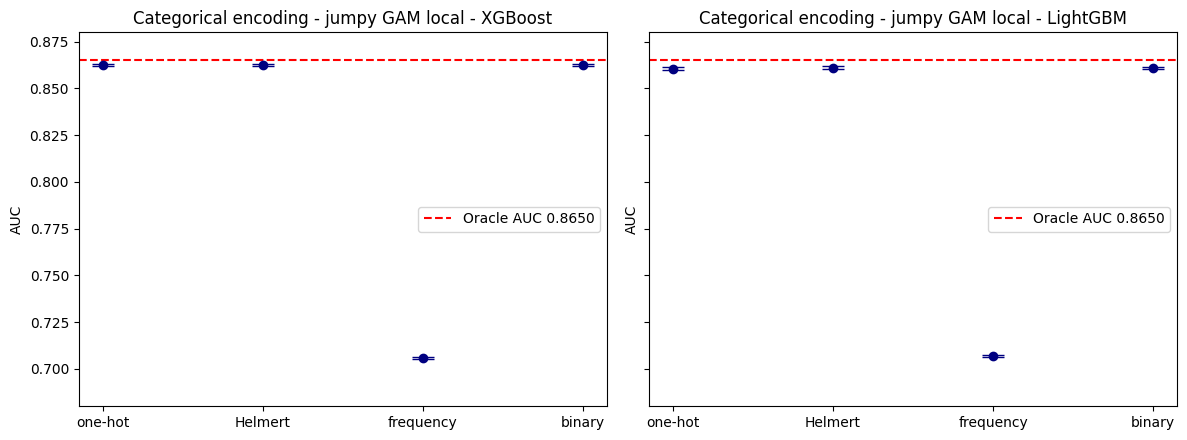

In [8]:
fig, panels = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for panel, model_name in zip(panels, ["XGBoost", "LightGBM"]):
    table = summary.loc[model_name].loc[encoding_methods]
    panel.errorbar(range(len(table)), table["mean"], yerr=table["plus_minus_2sd"],
                   fmt="o", capsize=8, color="navy")
    panel.axhline(oracle_auc, color="red", linestyle="--", label=f"Oracle AUC {oracle_auc:.4f}")
    panel.set_xticks(range(len(table)))
    panel.set_xticklabels(["one-hot", "Helmert", "frequency", "binary"])
    panel.set_ylim(0.68, 0.88)                         # leaves room below the frequency point
    panel.set_title(f"Categorical encoding - jumpy GAM local - {model_name}")
    panel.set_ylabel("AUC")
    panel.legend(loc="center right")                   # away from the points
plt.tight_layout()
plt.savefig("fig10_replication.png", dpi=150)
plt.show()

In [9]:
for model_name in ["XGBoost", "LightGBM"]:
    differences = []
    for k in range(3):
        one_hot_prediction = saved_predictions[(model_name, "one_hot")][k]
        helmert_prediction = saved_predictions[(model_name, "helmert")][k]
        differences.append(float(np.abs(one_hot_prediction - helmert_prediction).max()))
    print(f"{model_name}: largest difference between OHE and Helmert predictions on each validation set:",
          [f"{d:.2e}" for d in differences])

for model_name in ["XGBoost", "LightGBM"]:
    ohe = saved_split_counts[(model_name, "one_hot")]
    hel = saved_split_counts[(model_name, "helmert")]
    all_features = sorted(set(ohe) | set(hel),
                          key=lambda f: (f.startswith("cat_") or f.startswith("helmert_"), f))
    table = pd.DataFrame({"OHE": [ohe.get(f, 0) for f in all_features],
                          "Helmert": [hel.get(f, 0) for f in all_features]}, index=all_features)
    print(f"\n{model_name}: number of splits per feature (training set 1), like the paper's Table 3")
    print(table.to_string())
    ordinary = [f for f in all_features if not (f.startswith("cat_") or f.startswith("helmert_"))]
    print("   Ordinary features with equal counts:", int((table.loc[ordinary, "OHE"] == table.loc[ordinary, "Helmert"]).sum()),
          "of", len(ordinary))
    print("   Total splits on encoded columns -> OHE:", int(table.loc[[f for f in all_features if f.startswith('cat_')], 'OHE'].sum()),
          "| Helmert:", int(table.loc[[f for f in all_features if f.startswith('helmert_')], 'Helmert'].sum()))

XGBoost: largest difference between OHE and Helmert predictions on each validation set: ['0.00e+00', '0.00e+00', '0.00e+00']
LightGBM: largest difference between OHE and Helmert predictions on each validation set: ['8.31e-02', '8.44e-02', '7.69e-02']

XGBoost: number of splits per feature (training set 1), like the paper's Table 3
            OHE  Helmert
noise1     1318     1318
noise2     1603     1603
noise3     1731     1731
noise4     1436     1436
noise5     1516     1516
x1         1613     1613
x10        3477     3477
x2         2812     2812
x3         3797     3797
x4         2016     2016
x5         7361     7361
x6         1963     1963
x7         2273     2273
x8         2014     2014
x9         2014     2014
cat_is_0   1630        0
cat_is_1    898        0
cat_is_2    476        0
helmert_1     0     2528
helmert_2     0      476
   Ordinary features with equal counts: 15 of 15
   Total splits on encoded columns -> OHE: 3004 | Helmert: 3004

LightGBM: number of splits p

In [10]:
# ---------- Settings from the paper (Table 6, Appendix B.1) ----------
imp_numeric_features = 10
imp_noise_features = 5
imp_segments = 5                       # the categorical feature has 5 segments (Table 6)
imp_rows_per_segment = 50000           # 5 x 50,000 = 250,000 rows (paper: 250K)

# Covariance matrix (Eq. 4): neighbouring pairs correlated at 0.5
imp_covariance = np.eye(imp_numeric_features)
for i in range(0, imp_numeric_features, 2):
    imp_covariance[i, i + 1] = imp_covariance[i + 1, i] = 0.5

def make_imputation_dataset(seed, coefficients, rows_per_segment=imp_rows_per_segment):
    rows = rows_per_segment * imp_segments
    gen = np.random.default_rng(seed)

    # Part 3: feature values
    values = gen.multivariate_normal(np.zeros(imp_numeric_features), imp_covariance, rows)
    data = pd.DataFrame(values, columns=[f"x{i}" for i in range(1, 11)])
    for j in range(1, imp_noise_features + 1):
        data[f"noise{j}"] = gen.standard_normal(rows)                  # pure random numbers
    data["cat"] = gen.permutation(np.arange(rows) % imp_segments)      # categories 0..4, equal sizes

    # Part 1: the ten terms of the jumpy GAM local formula (Eq. 3), applied to every row
    b = coefficients
    x1, x2, x3, x4, x5, x6, x7, x8, x9, x10 = [data[f"x{i}"].values for i in range(1, 11)]
    logit = (b[0] * np.abs(x1) * (np.abs(x1) < 2)
           + b[1] * x2**2 * (x2 > 1)
           + b[2] * np.log(np.abs(x3) + 1) * (np.abs(x3) > 1)
           + np.exp(b[3] * x4) * (x4 < 0)
           + 1 / (b[4] * np.abs(x5) + 1)
           + b[5] * np.maximum(1, x6 + x7)
           + b[6] * (x7 < 1)
           + b[7] * (np.abs(x8) > 2)
           + b[8] * x9 * (x9 < -1)
           + b[9] * np.maximum(0, x10))

    # Part 4: logit -> probability (Eq. 5) -> random 0/1 label
    probability = 1 / (1 + np.exp(-logit))
    data["y"] = gen.binomial(1, probability)
    data["true_probability"] = probability
    return data

# ---------- Part 2: coefficients in [-3, 3], searched until the classes are balanced ----------
# (the paper says classes were inspected to be balanced but not how; this search is my method)
# The search uses small trial datasets (5 x 4,000 rows) so it runs fast.
imp_found = False
for coefficient_seed in range(300):
    imp_beta = np.random.default_rng(coefficient_seed).uniform(-3, 3, imp_numeric_features)
    trial = make_imputation_dataset(9999, imp_beta, rows_per_segment=4000)
    share = trial["y"].mean()
    auc_value = roc_auc_score(trial["y"], trial["true_probability"])
    if 0.45 <= share <= 0.55 and 0.88 <= auc_value <= 0.97:
        imp_found = True
        break

print("Coefficient seed found:", coefficient_seed if imp_found else "NONE in 300 tries")
print("Coefficients:", imp_beta.round(2))

# ---------- Build one full-size dataset (validation set 1) and check it ----------
imp_check = make_imputation_dataset(2000, imp_beta)
print("\nRows:", len(imp_check))
print("Rows per category:", imp_check["cat"].value_counts().sort_index().tolist())
print("Share of class 1:", imp_check["y"].mean().round(3))
print("Oracle AUC:", round(float(roc_auc_score(imp_check["y"], imp_check["true_probability"])), 4))
print("Correlation x1,x2 / x1,x3:", round(float(imp_check["x1"].corr(imp_check["x2"])), 2), "/",
      round(float(imp_check["x1"].corr(imp_check["x3"])), 2))

Coefficient seed found: 46
Coefficients: [ 2.43 -2.54 -1.36  0.73  2.6  -2.49  0.78  1.65  0.07  1.49]

Rows: 250000
Rows per category: [50000, 50000, 50000, 50000, 50000]
Share of class 1: 0.477
Oracle AUC: 0.8936
Correlation x1,x2 / x1,x3: 0.5 / 0.0


In [11]:
imp_null_columns = ["x1", "x4", "x6"]    # the three features that get missing values
imp_null_rate = 0.5                      # 50%, as in the paper

def inject_nulls(data, seed):
    with_nulls = data.copy()
    gen = np.random.default_rng(seed)
    for column in imp_null_columns:
        hidden = gen.random(len(with_nulls)) < imp_null_rate     # True for about 50% of rows
        with_nulls.loc[hidden, column] = np.nan
    return with_nulls

# ---------- Check on the dataset from N1 ----------
imp_check_with_nulls = inject_nulls(imp_check, seed=1)

print("Share of missing values per column:")
print(imp_check_with_nulls[imp_null_columns].isna().mean().round(3))
print("\nMissing values in all other columns:",
      int(imp_check_with_nulls.drop(columns=imp_null_columns).isna().sum().sum()))
print("Original dataset untouched, missing values:", int(imp_check[imp_null_columns].isna().sum().sum()))

print("\nFirst 6 rows, clean vs with nulls:")
print(pd.concat([imp_check[imp_null_columns].head(6),
                 imp_check_with_nulls[imp_null_columns].head(6).add_suffix("_with_nulls")], axis=1).round(3))

Share of missing values per column:
x1    0.501
x4    0.500
x6    0.501
dtype: float64

Missing values in all other columns: 0
Original dataset untouched, missing values: 0

First 6 rows, clean vs with nulls:
      x1     x4     x6  x1_with_nulls  x4_with_nulls  x6_with_nulls
0 -1.040  0.900  0.041         -1.040            NaN            NaN
1 -1.893 -0.358  0.314         -1.893            NaN          0.314
2 -2.198  0.458  2.451            NaN            NaN            NaN
3 -0.776  0.012 -0.235         -0.776          0.012            NaN
4 -0.998  0.005  0.458            NaN          0.005            NaN
5  1.516 -0.300  0.845            NaN         -0.300            NaN


In [13]:
from scipy.stats import ttest_ind
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

imp_numeric_columns = [f"x{i}" for i in range(1, 11)] + [f"noise{j}" for j in range(1, 6)]
imp_methods = ["mean", "median", "indicator", "decile", "cluster", "tree"]

def impute(method, train_with_nulls, other_with_nulls, seed=0):
    tr, te = train_with_nulls.copy(), other_with_nulls.copy()
    y = tr["y"].values

    if method in ("mean", "median"):
        for c in imp_null_columns:
            v = getattr(tr[c], method)()
            tr[c], te[c] = tr[c].fillna(v), te[c].fillna(v)

    elif method == "indicator":
        for c in imp_null_columns:
            tr[c + "_missing"] = tr[c].isna().astype(int)
            te[c + "_missing"] = te[c].isna().astype(int)
            tr[c], te[c] = tr[c].fillna(-9999), te[c].fillna(-9999)

    elif method == "decile":
        for c in imp_null_columns:
            x = tr[c].values
            observed = ~np.isnan(x)
            edges = np.quantile(x[observed], np.linspace(0, 1, 11))[1:-1]          # 9 cut points -> 10 groups
            group = np.searchsorted(edges, np.where(observed, x, 0))
            rates = np.array([y[observed & (group == k)].mean() for k in range(10)])
            closest = np.argmin(np.abs(rates - y[~observed].mean()))               # group most like the missing rows
            v = np.median(x[observed & (group == closest)])
            tr[c], te[c] = tr[c].fillna(v), te[c].fillna(v)

    elif method == "cluster":
        medians = tr[imp_numeric_columns].median()
        scaler = StandardScaler().fit(tr[imp_numeric_columns].fillna(medians))
        scaled_tr = scaler.transform(tr[imp_numeric_columns].fillna(medians))
        scaled_te = scaler.transform(te[imp_numeric_columns].fillna(medians))
        sample = np.random.default_rng(seed).choice(len(scaled_tr), size=min(50000, len(scaled_tr)), replace=False)
        kmeans = KMeans(5, n_init=3, random_state=seed).fit(scaled_tr[sample])
        cluster_tr = pd.Series(kmeans.predict(scaled_tr), index=tr.index)
        cluster_te = pd.Series(kmeans.predict(scaled_te), index=te.index)
        for c in imp_null_columns:
            cluster_mean = tr[c].groupby(cluster_tr).mean()          # mean of observed values in each cluster
            tr[c] = tr[c].fillna(cluster_tr.map(cluster_mean))
            te[c] = te[c].fillna(cluster_te.map(cluster_mean))

    elif method == "tree":
        for c in imp_null_columns:
            x = tr[c].values
            observed = ~np.isnan(x)
            xo = x[observed].reshape(-1, 1)
            tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=seed)
            tree.fit(xo, y[observed])
            leaf = tree.apply(xo)
            best_leaf = min(np.unique(leaf),
                            key=lambda l: abs(ttest_ind(y[observed][leaf == l], y[~observed],
                                                        equal_var=False).statistic))
            v = np.median(xo[leaf == best_leaf])
            tr[c], te[c] = tr[c].fillna(v), te[c].fillna(v)

    return tr, te

# ---------- Check: training = dataset from N1 with nulls, "other" = validation-style data with nulls ----------
imp_train_with_nulls = inject_nulls(imp_check, seed=100)
imp_other_with_nulls = inject_nulls(make_imputation_dataset(2001, imp_beta), seed=200)

for method in imp_methods:
    method_start = time.time()
    tr, te = impute(method, imp_train_with_nulls, imp_other_with_nulls)
    filled_value = tr.loc[imp_train_with_nulls["x1"].isna(), "x1"]
    print(f"{method:<10} columns: {tr.shape[1]} | NaN left in null columns (train/other): "
          f"{int(tr[imp_null_columns].isna().sum().sum())} / {int(te[imp_null_columns].isna().sum().sum())} "
          f"| x1 fill values used: {filled_value.nunique()} different "
          f"| {time.time()-method_start:.0f} s")

mean       columns: 18 | NaN left in null columns (train/other): 0 / 0 | x1 fill values used: 1 different | 0 s
median     columns: 18 | NaN left in null columns (train/other): 0 / 0 | x1 fill values used: 1 different | 0 s
indicator  columns: 21 | NaN left in null columns (train/other): 0 / 0 | x1 fill values used: 1 different | 0 s
decile     columns: 18 | NaN left in null columns (train/other): 0 / 0 | x1 fill values used: 1 different | 0 s
cluster    columns: 18 | NaN left in null columns (train/other): 0 / 0 | x1 fill values used: 5 different | 1 s
tree       columns: 18 | NaN left in null columns (train/other): 0 / 0 | x1 fill values used: 1 different | 0 s


In [14]:
# The paper's 3 validation sets for this experiment (same coefficients, different random draws)
imp_validation_sets = [make_imputation_dataset(2000 + i, imp_beta) for i in range(3)]
imp_oracle_auc = np.mean([roc_auc_score(d["y"], d["true_probability"]) for d in imp_validation_sets])
rows_per_valid = len(imp_validation_sets[0])

# Validation data stacked into one table (so each imputation method is applied once), clean and with nulls
imp_valid_clean = pd.concat(imp_validation_sets, ignore_index=True)
imp_valid_nulls = pd.concat([inject_nulls(d, 200 + k) for k, d in enumerate(imp_validation_sets)],
                            ignore_index=True)

def model_table(data):
    # Standard preprocessing: one-hot the categorical column. (Standardizing numeric columns is left out
    # because it cannot change the result of tree models.)
    base = data.drop(columns=["y", "true_probability", "cat"])
    one_hot = pd.DataFrame({f"cat_is_{k}": (data["cat"] == k).astype(int) for k in range(5)}, index=data.index)
    return pd.concat([base, one_hot], axis=1)

def average_validation_auc(model, X_valid, y_valid):
    p = model.predict_proba(X_valid)[:, 1]
    return float(np.mean([roc_auc_score(y_valid[k*rows_per_valid:(k+1)*rows_per_valid],
                                        p[k*rows_per_valid:(k+1)*rows_per_valid]) for k in range(3)]))

def run_imputation_training_set(i):
    clean_train = make_imputation_dataset(1000 + i, imp_beta)
    train_with_nulls = inject_nulls(clean_train, 100 + i)
    rows = []
    for method in ["no_missing"] + imp_methods:
        if method == "no_missing":
            tr, te = clean_train, imp_valid_clean
        else:
            tr, te = impute(method, train_with_nulls, imp_valid_nulls, seed=i)
        X_train, X_valid = model_table(tr), model_table(te)
        for model_name in ["XGBoost", "LightGBM"]:
            model = make_model(model_name).fit(X_train, tr["y"])          # tuned settings from the core experiment
            rows.append((model_name, method, i, average_validation_auc(model, X_valid, te["y"].values)))
    return rows

# ---------- Timing test: training set 1 only ----------
start = time.time()
imp_test_rows = run_imputation_training_set(0)
elapsed = time.time() - start

print("Oracle AUC (mean of 3 validation sets):", round(float(imp_oracle_auc), 4))
print(f"\nOne training set (14 models) took {elapsed/60:.1f} min")
print(f"Estimated time for all 30 training sets: {30*elapsed/3600:.1f} hours\n")
for model_name, method, _, auc_value in imp_test_rows:
    print(f"{model_name:<9} {method:<11} AUC {auc_value:.4f}")


Oracle AUC (mean of 3 validation sets): 0.893

One training set (14 models) took 4.1 min
Estimated time for all 30 training sets: 2.0 hours

XGBoost   no_missing  AUC 0.8895
LightGBM  no_missing  AUC 0.8886
XGBoost   mean        AUC 0.8476
LightGBM  mean        AUC 0.8469
XGBoost   median      AUC 0.8475
LightGBM  median      AUC 0.8470
XGBoost   indicator   AUC 0.8478
LightGBM  indicator   AUC 0.8473
XGBoost   decile      AUC 0.8472
LightGBM  decile      AUC 0.8469
XGBoost   cluster     AUC 0.8456
LightGBM  cluster     AUC 0.8447
XGBoost   tree        AUC 0.8477
LightGBM  tree        AUC 0.8473


In [15]:
# Keep the settings tuned for the categorical-encoding experiment
core_xgboost_settings = dict(best_xgboost_settings)
core_lightgbm_settings = dict(best_lightgbm_settings)

# The paper's 3 tuning datasets for this experiment, each with 50% missing values in x1, x4, x6
imp_tuning_sets = [make_imputation_dataset(3000 + i, imp_beta) for i in range(3)]
tune_train = pd.concat([inject_nulls(imp_tuning_sets[0], 300),
                        inject_nulls(imp_tuning_sets[1], 301)], ignore_index=True)
tune_valid = inject_nulls(imp_tuning_sets[2], 302)

# Missing values filled with the mean (statistics from the tuning training data only)
tune_train_filled, tune_valid_filled = impute("mean", tune_train, tune_valid)
X_imp_tune_train = model_table(tune_train_filled)
X_imp_tune_valid = model_table(tune_valid_filled)
print("Tuning rows:", len(X_imp_tune_train), "(train) /", len(X_imp_tune_valid), "(validation)")

def score_imp_xgboost(trial):
    model = xgb.XGBClassifier(
        n_estimators=trial.suggest_int("n_estimators", 50, 400),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        max_depth=trial.suggest_int("max_depth", 2, 8),
        gamma=trial.suggest_float("gamma", 0, 5),
        tree_method="hist", random_state=0, eval_metric="logloss")
    model.fit(X_imp_tune_train, tune_train_filled["y"])
    return roc_auc_score(tune_valid_filled["y"], model.predict_proba(X_imp_tune_valid)[:, 1])

def score_imp_lightgbm(trial):
    model = lgb.LGBMClassifier(
        n_estimators=trial.suggest_int("n_estimators", 50, 400),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        max_depth=trial.suggest_int("max_depth", 2, 8),
        min_split_gain=trial.suggest_float("min_split_gain", 0, 5),
        random_state=0, verbose=-1)
    model.fit(X_imp_tune_train, tune_train_filled["y"])
    return roc_auc_score(tune_valid_filled["y"], model.predict_proba(X_imp_tune_valid)[:, 1])

start = time.time()
imp_xgb_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=0))
imp_xgb_study.optimize(score_imp_xgboost, n_trials=20)
print(f"XGBoost tuning finished in {(time.time()-start)/60:.1f} min")

start = time.time()
imp_lgb_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=0))
imp_lgb_study.optimize(score_imp_lightgbm, n_trials=20)
print(f"LightGBM tuning finished in {(time.time()-start)/60:.1f} min")

# The full imputation run uses these settings from now on
best_xgboost_settings = imp_xgb_study.best_params
best_lightgbm_settings = imp_lgb_study.best_params

print("\nXGBoost  best AUC:", round(imp_xgb_study.best_value, 4))
for name, value in best_xgboost_settings.items():
    print("   ", name, "=", round(value, 4) if isinstance(value, float) else value)
print("LightGBM best AUC:", round(imp_lgb_study.best_value, 4))
for name, value in best_lightgbm_settings.items():
    print("   ", name, "=", round(value, 4) if isinstance(value, float) else value)

Tuning rows: 500000 (train) / 250000 (validation)
XGBoost tuning finished in 2.8 min
LightGBM tuning finished in 4.3 min

XGBoost  best AUC: 0.8495
    n_estimators = 198
    learning_rate = 0.09
    max_depth = 5
    gamma = 4.4589
LightGBM best AUC: 0.8496
    n_estimators = 264
    learning_rate = 0.0815
    max_depth = 8
    min_split_gain = 3.4091


In [16]:
if "imp_all_rows" not in globals():       # so re-running this cell resumes instead of restarting
    imp_all_rows, imp_completed = [], set()

number_of_imputation_sets = 30            # paper: 30
imp_run_start = time.time()
sets_done_this_run = 0

for i in range(number_of_imputation_sets):
    if i in imp_completed:
        continue
    set_start = time.time()
    imp_all_rows.extend(run_imputation_training_set(i))
    imp_completed.add(i)
    sets_done_this_run += 1
    pd.DataFrame(imp_all_rows, columns=["model", "method", "training_set", "auc"]).to_csv("imputation_results.csv", index=False)
    minutes_left = (time.time() - imp_run_start) / 60 / sets_done_this_run * (number_of_imputation_sets - len(imp_completed))
    print(f"Training set {i+1}/{number_of_imputation_sets} done in {(time.time()-set_start)/60:.1f} min "
          f"| about {minutes_left:.0f} min left")

# ---------- Summary (paper's Fig 15 numbers): mean and +/- 2 SD over the training sets ----------
imp_results = pd.DataFrame(imp_all_rows, columns=["model", "method", "training_set", "auc"])
imp_summary = imp_results.groupby(["model", "method"])["auc"].agg(["mean", "std", "count"])
imp_summary["plus_minus_2sd"] = 2 * imp_summary["std"]
print(imp_summary.round(4))
print("\nOracle AUC (mean of 3 validation sets):", round(float(imp_oracle_auc), 4))

Training set 1/30 done in 2.1 min | about 61 min left
Training set 2/30 done in 2.1 min | about 59 min left
Training set 3/30 done in 2.1 min | about 57 min left
Training set 4/30 done in 2.1 min | about 55 min left
Training set 5/30 done in 2.1 min | about 53 min left
Training set 6/30 done in 2.1 min | about 50 min left
Training set 7/30 done in 2.1 min | about 48 min left
Training set 8/30 done in 2.1 min | about 46 min left
Training set 9/30 done in 2.1 min | about 44 min left
Training set 10/30 done in 2.1 min | about 42 min left
Training set 11/30 done in 2.1 min | about 40 min left
Training set 12/30 done in 2.1 min | about 38 min left
Training set 13/30 done in 2.1 min | about 36 min left
Training set 14/30 done in 2.1 min | about 34 min left
Training set 15/30 done in 2.1 min | about 31 min left
Training set 16/30 done in 2.1 min | about 29 min left
Training set 17/30 done in 2.1 min | about 27 min left
Training set 18/30 done in 2.1 min | about 25 min left
Training set 19/30 

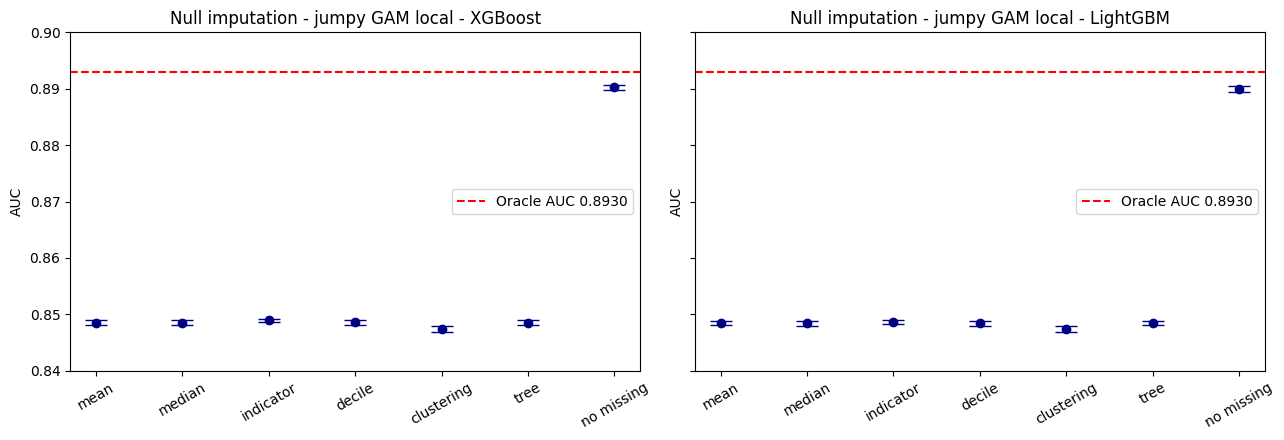

In [17]:
method_order = ["mean", "median", "indicator", "decile", "cluster", "tree", "no_missing"]
method_labels = ["mean", "median", "indicator", "decile", "clustering", "tree", "no missing"]

fig, panels = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for panel, model_name in zip(panels, ["XGBoost", "LightGBM"]):
    table = imp_summary.loc[model_name].loc[method_order]
    panel.errorbar(range(len(table)), table["mean"], yerr=table["plus_minus_2sd"],
                   fmt="o", capsize=8, color="navy")
    panel.axhline(imp_oracle_auc, color="red", linestyle="--", label=f"Oracle AUC {imp_oracle_auc:.4f}")
    panel.set_xticks(range(len(table)))
    panel.set_xticklabels(method_labels, rotation=30)
    panel.set_ylim(0.84, 0.90)
    panel.set_title(f"Null imputation - jumpy GAM local - {model_name}")
    panel.set_ylabel("AUC")
    panel.legend(loc="center right")
plt.tight_layout()
plt.savefig("fig15_replication.png", dpi=150)
plt.show()